# Imports

In [ ]:
# Import the library to mount Google Drive
from google.colab import drive

import h5py
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

In [2]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


# Initialization

In [4]:
file_name = "230K_reflection_high_res_test_0.2_val_0.2.h5"
file_path = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name}"
data_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"

In [ ]:
import h5py
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split


In [ ]:
file_path = f"/Users/UserB/Documents/Github/OrgA/project/Data/1.84M_pyCrysfml_high_res.hdf5"

In [ ]:
def print_hdf5_structure(name, obj):
    print(name)

with h5py.File(file_path, "r") as f:
    f.visititems(print_hdf5_structure)

2theta
SG_100
SG_100/intensity
SG_105
SG_105/intensity
SG_108
SG_108/intensity
SG_11
SG_11/intensity
SG_110
SG_110/intensity
SG_114
SG_114/intensity
SG_118
SG_118/intensity
SG_120
SG_120/intensity
SG_127
SG_127/intensity
SG_13
SG_13/intensity
SG_134
SG_134/intensity
SG_135
SG_135/intensity
SG_136
SG_136/intensity
SG_139
SG_139/intensity
SG_141
SG_141/intensity
SG_144
SG_144/intensity
SG_145
SG_145/intensity
SG_147
SG_147/intensity
SG_149
SG_149/intensity
SG_153
SG_153/intensity
SG_156
SG_156/intensity
SG_158
SG_158/intensity
SG_159
SG_159/intensity
SG_161
SG_161/intensity
SG_164
SG_164/intensity
SG_168
SG_168/intensity
SG_170
SG_170/intensity
SG_171
SG_171/intensity
SG_172
SG_172/intensity
SG_173
SG_173/intensity
SG_174
SG_174/intensity
SG_176
SG_176/intensity
SG_181
SG_181/intensity
SG_185
SG_185/intensity
SG_186
SG_186/intensity
SG_187
SG_187/intensity
SG_189
SG_189/intensity
SG_19
SG_19/intensity
SG_193
SG_193/intensity
SG_195
SG_195/intensity
SG_196
SG_196/intensity
SG_198
SG_198/i

# ml_ready and data split - Data Load

In [ ]:
import h5py
import numpy as np

#file_path = "your_file.h5"

with h5py.File(file_path, "r") as f:
    print("\n--- Exploring HDF5 File ---")

    # 1. Data splits
    print("\n[ data_split ]")
    for key in f["data_split"].keys():
        data = f["data_split"][key][:]
        print(f"{key}: shape = {data.shape}, dtype = {data.dtype}, min = {data.min()}, max = {data.max()}")

    # 2. ML-ready datasets
    print("\n[ ml_ready ]")
    for key in f["ml_ready"].keys():
        data = f["ml_ready"][key][:]
        print(f"{key}: shape = {data.shape}, dtype = {data.dtype}")
        if key in ("intensity", "twotheta"):
            print(f"  min = {data.min():.2f}, max = {data.max():.2f}, mean = {data.mean():.2f}, std = {data.std():.2f}")
            print(f"  first 5 values: {data[:5]}")
        elif key == "space_groups":
            unique_sg, counts = np.unique(data, return_counts=True)
            print(f"  unique space groups: {len(unique_sg)}")
            for sg, count in zip(unique_sg, counts):
                print(f"    SG_{sg}: {count} patterns")

    # 3. Pattern-level data (optional preview of a few patterns)
    print("\n[ patterns ]")
    sg_groups = list(f["patterns"].keys())
    print(f"Found {len(sg_groups)} space groups: {sg_groups[:5]}{' ...' if len(sg_groups) > 5 else ''}")

    for sg in sg_groups[:2]:  # Limit to first 2 SGs for quick preview
        pattern_group = f[f"patterns/{sg}"]
        pattern_keys = list(pattern_group.keys())
        print(f"\nSpace Group {sg}: {len(pattern_keys)} patterns")
        for pattern_name in pattern_keys[:2]:  # Show first 2 patterns
            p = pattern_group[pattern_name]
            intensity = p["intensity"][:]
            twotheta = p["twotheta"][:]
            print(f"  {pattern_name}:")
            print(f"    intensity shape: {intensity.shape}, twotheta shape: {twotheta.shape}")
            print(f"    intensity range: {intensity.min():.2f} to {intensity.max():.2f}")
            print(f"    twotheta range: {twotheta.min():.2f} to {twotheta.max():.2f}")
            print(f"    first 5 twotheta: {twotheta[:5]}")
            print(f"    first 5 intensity: {intensity[:5]}")



--- Exploring HDF5 File ---

[ data_split ]
test_indices: shape = (23000,), dtype = int64, min = 10, max = 229989
train_indices: shape = (184000,), dtype = int64, min = 0, max = 229999
validation_indices: shape = (23000,), dtype = int64, min = 12, max = 229995

[ ml_ready ]
intensity: shape = (230000, 1000), dtype = float32
  min = 0.00, max = 1000.00, mean = 55.64, std = 133.78
  first 5 values: [[0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 2.0487161e+02
  2.4648653e+02 3.5317209e+02]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 3.7022301e+01
  3.4528000e+02 8.3181348e+02]
 [0.0000000e+00 1.9916655e-41 1.5502875e-32 ... 5.5981116e+02
  3.1519263e+02 1.3581546e+02]
 [7.6485467e-01 3.3851299e+01 1.3396512e+02 ... 3.4672925e+02
  2.8236871e+02 3.2846396e+02]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 2.6090057e+02
  2.6378305e+02 8.2612465e+01]]
masks: shape = (230000, 1000), dtype = int8
space_groups: shape = (230000,), dtype = int32
  unique space groups: 230
    SG_1: 1000 

# ml-ready and data split - EDA



In [ ]:
import h5py
import numpy as np

#file_path = "your_file.h5"  # Replace with your actual path

# Storage for all intensity values
all_intensities = []
all_thetas = []

with h5py.File(file_path, "r") as f:
    patterns_group = f.get("patterns")
    if patterns_group is None:
        raise KeyError("Missing 'patterns' group in HDF5 file.")

    # Iterate over all SG subgroups (e.g., sg_1, sg_2, ...)
    for sg_name in patterns_group:
        sg_group = patterns_group[sg_name]
        for pattern_name in sg_group:
            try:
                pattern = sg_group[pattern_name]
                theta = pattern["twotheta"][:]
                intensity = pattern["intensity"][:]

                all_thetas.append(theta)
                all_intensities.append(intensity)

                print(f"Loaded {sg_name}/{pattern_name}: theta shape:{theta.shape}, intensity shape:{intensity.shape}")
            except KeyError as e:
                print(f"Skipping {sg_name}/{pattern_name}, missing datasets: {e}")

# Convert to numpy arrays
all_thetas = np.concatenate(all_thetas) if all_thetas else np.array([])
all_intensities = np.concatenate(all_intensities) if all_intensities else np.array([])

# Summary statistics
summary = {
    "num_spectra": len(all_intensities),
    "2theta_min": np.min(all_thetas) if all_thetas.size > 0 else None,
    "2theta_max": np.max(all_thetas) if all_thetas.size > 0 else None,
    "intensity_min": np.min(all_intensities) if all_intensities.size > 0 else None,
    "intensity_max": np.max(all_intensities) if all_intensities.size > 0 else None,
    "intensity_mean": np.mean(all_intensities) if all_intensities.size > 0 else None,
    "intensity_std": np.std(all_intensities) if all_intensities.size > 0 else None,
}

# Print summary
print("\n--- Summary Statistics ---")
for key, value in summary.items():
    print(f"{key}: {value}")


Streaming output truncated to the last 5000 lines.
Loaded sg_95/pattern_106: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_107: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_108: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_109: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_11: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_110: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_111: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_112: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_113: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_114: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_115: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_116: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_117: theta shape:(1000,), intensity shape:(1000,)
Loaded sg_95/pattern_118: t

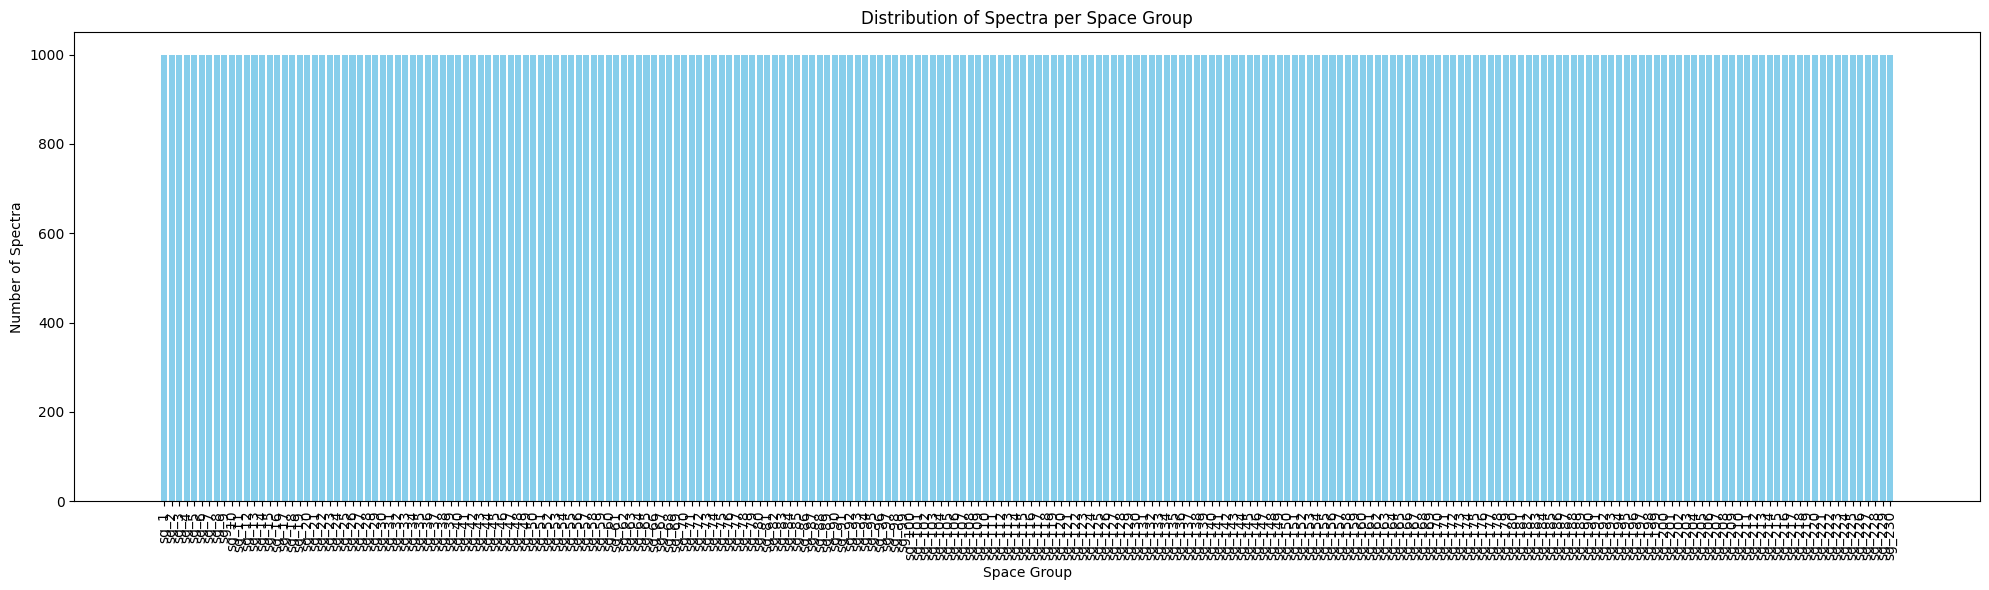

In [ ]:
import h5py
import matplotlib.pyplot as plt
from collections import defaultdict

#file_path = "your_file.h5"  # Replace with your actual file path

# Dictionary to store count per SG group
sg_counts = defaultdict(int)

with h5py.File(file_path, "r") as f:
    patterns_group = f.get("patterns")
    if patterns_group is None:
        raise KeyError("Missing 'patterns' group in HDF5 file.")

    for sg_name in patterns_group:
        sg_group = patterns_group[sg_name]
        count = 0
        for pattern_name in sg_group:
            if "intensity" in sg_group[pattern_name]:
                count += 1
        sg_counts[sg_name] = count

# Sort space groups numerically by their integer part (e.g., sg_1 -> 1)
sorted_sg = sorted(sg_counts.items(), key=lambda x: int(x[0].split('_')[1]))

# Unpack for plotting
sg_labels, counts = zip(*sorted_sg)

# Plotting
plt.figure(figsize=(20, 6))
plt.bar(sg_labels, counts, color='skyblue')
plt.xticks(rotation=90)
plt.xlabel("Space Group")
plt.ylabel("Number of Spectra")
plt.title("Distribution of Spectra per Space Group")
plt.tight_layout()
plt.show()


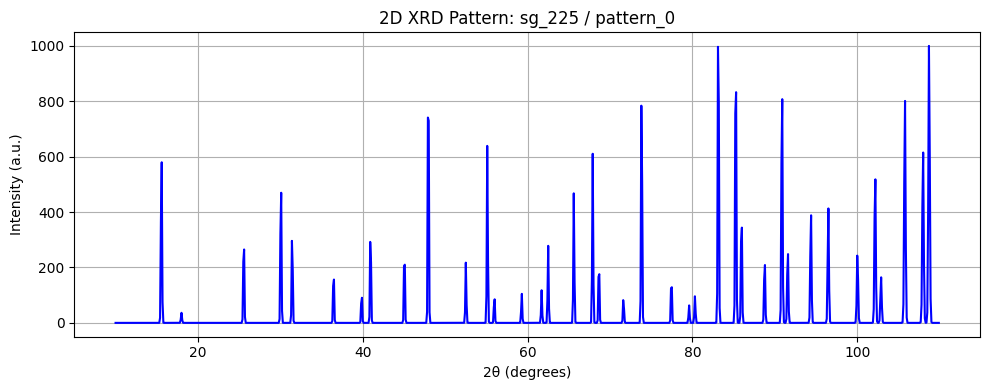

In [ ]:
import h5py
import matplotlib.pyplot as plt

#file_path = "your_file.h5"  # Replace with your actual file path
sg = "sg_225"
pattern = "pattern_0"

with h5py.File(file_path, "r") as f:
    twotheta = f[f"patterns/{sg}/{pattern}/twotheta"][:]
    intensity = f[f"patterns/{sg}/{pattern}/intensity"][:]

# Plot the 2D pattern
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity, color='blue')
plt.title(f"2D XRD Pattern: {sg} / {pattern}")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()


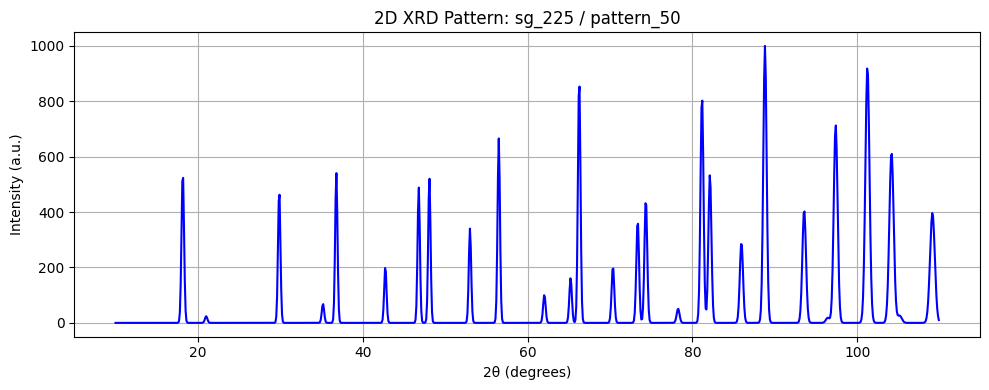

In [ ]:
import h5py
import matplotlib.pyplot as plt

#file_path = "your_file.h5"  # Replace with your actual file path
sg = "sg_225"
pattern = "pattern_50"

with h5py.File(file_path, "r") as f:
    twotheta = f[f"patterns/{sg}/{pattern}/twotheta"][:]
    intensity = f[f"patterns/{sg}/{pattern}/intensity"][:]

# Plot the 2D pattern
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity, color='blue')
plt.title(f"2D XRD Pattern: {sg} / {pattern}")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()

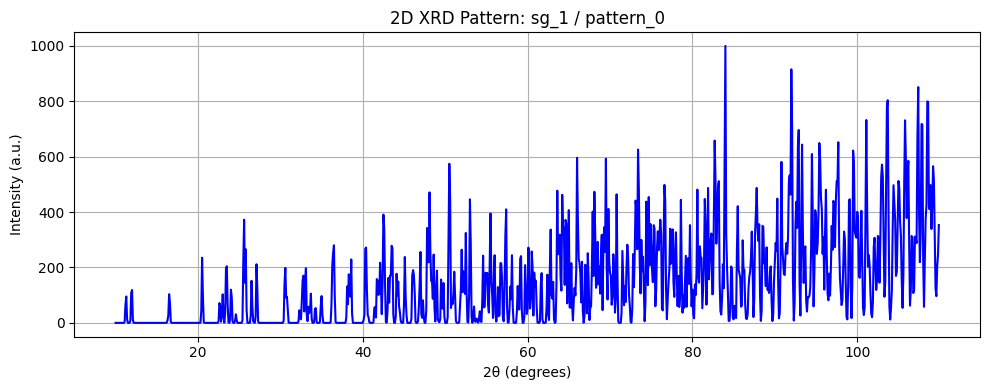

In [ ]:
import h5py
import matplotlib.pyplot as plt

#file_path = "your_file.h5"  # Replace with your actual file path
sg = "sg_1"
pattern = "pattern_0"

with h5py.File(file_path, "r") as f:
    twotheta = f[f"patterns/{sg}/{pattern}/twotheta"][:]
    intensity = f[f"patterns/{sg}/{pattern}/intensity"][:]

# Plot the 2D pattern
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity, color='blue')
plt.title(f"2D XRD Pattern: {sg} / {pattern}")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()

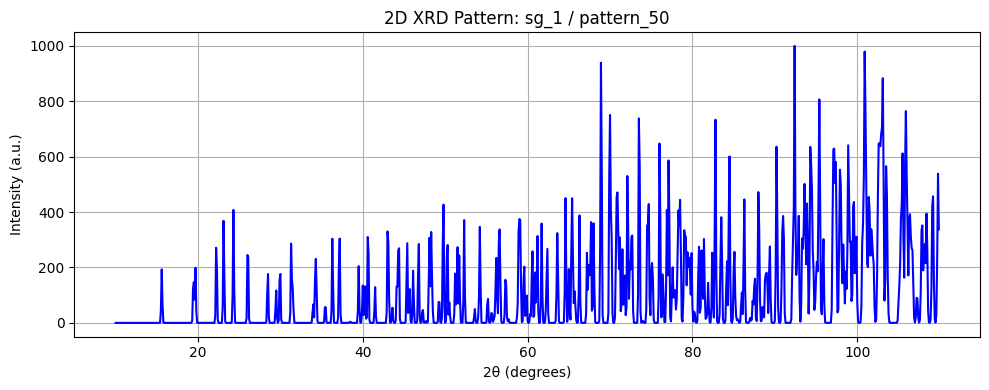

In [ ]:
import h5py
import matplotlib.pyplot as plt

#file_path = "your_file.h5"  # Replace with your actual file path
sg = "sg_1"
pattern = "pattern_50"

with h5py.File(file_path, "r") as f:
    twotheta = f[f"patterns/{sg}/{pattern}/twotheta"][:]
    intensity = f[f"patterns/{sg}/{pattern}/intensity"][:]

# Plot the 2D pattern
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity, color='blue')
plt.title(f"2D XRD Pattern: {sg} / {pattern}")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()

# ml ready and data split - Data Split and Save

In [ ]:
import h5py
import numpy as np
import re
from tqdm import tqdm

#file_path = "your_file.h5"  # Replace with actual path

X = []
y = []

with h5py.File(file_path, "r") as f:
    pattern_root = f["patterns"]

    for sg_name in tqdm(pattern_root.keys()):
        if not sg_name.startswith("sg_"):
            continue

        sg_id = int(re.findall(r"\d+", sg_name)[0])  # extract number from sg_XX
        sg_group = pattern_root[sg_name]

        for pattern_name in sg_group.keys():
            pattern_group = sg_group[pattern_name]

            try:
                intensity = pattern_group["intensity"][:]
                if intensity.ndim > 1:
                    intensity = intensity.squeeze()

                # Normalize length to 1,000
                if len(intensity) > 1000:
                    trimmed = intensity[:1000]
                else:
                    trimmed = np.pad(intensity, (0, 1000 - len(intensity)))

                X.append(trimmed)
                y.append(sg_id)

            except KeyError:
                print(f"Skipping {sg_name}/{pattern_name}, missing intensity")
                continue

X = np.stack(X)
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")


100%|██████████| 230/230 [02:20<00:00,  1.64it/s]


X shape: (230000, 1000), y shape: (230000,)


In [ ]:

test_split = 0.20
validation_split = 0.20

X1 = torch.tensor(X, dtype=torch.float)
y1 = torch.tensor(y, dtype=torch.long)

# First split: Train/Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

# Second split: Train/Validation (80/20 of the original training set)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

# # Save to HDF5
# with h5py.File(output_path + f"{datasource}_{intensity_points}_{space}_{twotheta_start}_{twotheta_end}_{test_split}_{validation_split}.h5", "w") as f:
#     f.create_dataset("X_train", data=X_train)
#     f.create_dataset("y_train", data=y_train)
#     f.create_dataset("X_val", data=X_val)
#     f.create_dataset("y_val", data=y_val)
#     f.create_dataset("X_test", data=X_test)
#     f.create_dataset("y_test", data=y_test)

#save_path = "/content/drive/My Drive/dataset.h5"

with h5py.File(f"{data_path}{file_name}_test_{test_split}_val_{validation_split}.h5", "w") as f:
    f.create_dataset("X_train", data=X_train)
    f.create_dataset("y_train", data=y_train)
    f.create_dataset("X_val", data=X_val)
    f.create_dataset("y_val", data=y_val)
    f.create_dataset("X_test", data=X_test)
    f.create_dataset("y_test", data=y_test)

print(f"Data successfully split and saved to {data_path}{file_name}_test_{test_split}_val_{validation_split}.h5")

Data successfully split and saved to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_reflection_high_res.h5_test_0.2_val_0.2.h5


# pattern data only - Data Load

In [ ]:
import h5py
import numpy as np

#file_path = "your_new_file.h5"  # Replace with actual file path

with h5py.File(file_path, "r") as f:
    print("\n--- Exploring HDF5 File ---")

    # 1. List all space groups at the root level
    sg_groups = list(f.keys())
    print(f"Found {len(sg_groups)} space groups:")
    print(sg_groups[:5], "..." if len(sg_groups) > 5 else "")

    total_patterns = 0  # Counter for total patterns across all SGs

    # 2. Explore each space group
    for sg in sg_groups:
        sg_group = f[sg]

        if "2theta" in sg_group and "intensity" in sg_group:
            intensity = sg_group["intensity"][:]

            # Determine pattern count
            if intensity.ndim == 1:
                num_patterns = 1
            elif intensity.ndim == 2:
                num_patterns = intensity.shape[0]
            else:
                num_patterns = 0  # Unusual case

            total_patterns += num_patterns

        else:
            print(f"  Missing '2theta' or 'intensity' dataset in {sg}")

    print(f"\nTotal patterns across all space groups: {total_patterns}")
    print("\n--- Exploration Complete ---")



--- Exploring HDF5 File ---
Found 230 space groups:
['SG_1', 'SG_10', 'SG_100', 'SG_101', 'SG_102'] ...

Total patterns across all space groups: 230000

--- Exploration Complete ---


# pattern data only - EDA

In [ ]:
import h5py
import numpy as np

#file_path = "your_file.h5"  # Replace with your actual path

# Storage for all intensity values
all_intensities = []
all_thetas = []

with h5py.File(file_path, "r") as f:
    # Iterate over all space groups (e.g., SG_1, SG_10, ...)
    for sg_name in f.keys():
        sg_group = f[sg_name]
        try:
            theta = sg_group["2theta"][:]
            intensity = sg_group["intensity"][:]

            # Check shape
            if intensity.ndim == 1:
                # Single pattern
                all_thetas.append(theta)
                all_intensities.append(intensity)
                print(f"Loaded {sg_name}: theta shape:{theta.shape}, intensity shape:{intensity.shape}")
            elif intensity.ndim == 2:
                # Multiple patterns in a 2D array
                for i in range(intensity.shape[0]):
                    all_thetas.append(theta)
                    all_intensities.append(intensity[i])
                print(f"Loaded {sg_name}: {intensity.shape[0]} patterns (theta shape:{theta.shape})")
            else:
                print(f"Skipping {sg_name}, unexpected intensity shape:{intensity.shape}")
        except KeyError as e:
            print(f"Skipping {sg_name}, missing datasets: {e}")

# Convert to numpy arrays
all_thetas = np.concatenate(all_thetas) if all_thetas else np.array([])
all_intensities = np.concatenate(all_intensities) if all_intensities else np.array([])

# Summary statistics
summary = {
    "num_spectra": len(all_intensities) if all_intensities.ndim == 1 else all_intensities.shape[0],
    "2theta_min": np.min(all_thetas) if all_thetas.size > 0 else None,
    "2theta_max": np.max(all_thetas) if all_thetas.size > 0 else None,
    "intensity_min": np.min(all_intensities) if all_intensities.size > 0 else None,
    "intensity_max": np.max(all_intensities) if all_intensities.size > 0 else None,
    "intensity_mean": np.mean(all_intensities) if all_intensities.size > 0 else None,
    "intensity_std": np.std(all_intensities) if all_intensities.size > 0 else None,
}

# Print summary
print("\n--- Summary Statistics ---")
for key, value in summary.items():
    print(f"{key}: {value}")


Loaded SG_1: 963 patterns (theta shape:(3041,))
Loaded SG_10: 996 patterns (theta shape:(3041,))
Loaded SG_100: 992 patterns (theta shape:(3041,))
Loaded SG_101: 979 patterns (theta shape:(3041,))
Loaded SG_102: 1001 patterns (theta shape:(3041,))
Loaded SG_103: 1007 patterns (theta shape:(3041,))
Loaded SG_104: 1062 patterns (theta shape:(3041,))
Loaded SG_105: 1006 patterns (theta shape:(3041,))
Loaded SG_106: 1010 patterns (theta shape:(3041,))
Loaded SG_107: 1027 patterns (theta shape:(3041,))
Loaded SG_108: 994 patterns (theta shape:(3041,))
Loaded SG_109: 963 patterns (theta shape:(3041,))
Loaded SG_11: 1037 patterns (theta shape:(3041,))
Loaded SG_110: 988 patterns (theta shape:(3041,))
Loaded SG_111: 1040 patterns (theta shape:(3041,))
Loaded SG_112: 1006 patterns (theta shape:(3041,))
Loaded SG_113: 1029 patterns (theta shape:(3041,))
Loaded SG_114: 1014 patterns (theta shape:(3041,))
Loaded SG_115: 1008 patterns (theta shape:(3041,))
Loaded SG_116: 969 patterns (theta shape:(

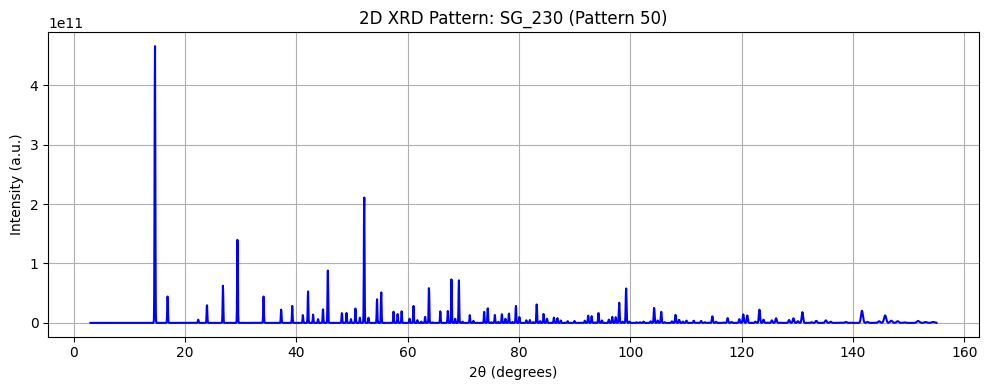

In [ ]:
import h5py
import matplotlib.pyplot as plt

# file_path = "your_file.h5"  # Replace with your actual file path
sg = "SG_230"  # Example space group
pattern_index = 50  # Pattern index to select (0-based)

with h5py.File(file_path, "r") as f:
    if sg not in f:
        raise KeyError(f"Space group '{sg}' not found in the file.")

    sg_group = f[sg]

    if "intensity" not in sg_group or "2theta" not in sg_group:
        raise KeyError(f"Required datasets 'intensity' or '2theta' not found in '{sg}'.")

    intensity_data = sg_group["intensity"][:]  # shape (num_patterns, num_points)
    twotheta_data = sg_group["2theta"][:]      # shape (num_points,)

    # Check intensity data shape
    if intensity_data.ndim == 2:
        num_patterns = intensity_data.shape[0]
        if pattern_index >= num_patterns:
            raise IndexError(f"Pattern index {pattern_index} out of range (0 to {num_patterns-1}).")
        intensity = intensity_data[pattern_index, :]
        twotheta = twotheta_data
    elif intensity_data.ndim == 1:
        print(f"Single pattern found in {sg}. Plotting without index selection.")
        intensity = intensity_data
        twotheta = twotheta_data
    else:
        raise ValueError(f"Unexpected data shape: intensity {intensity_data.shape}, 2theta {twotheta_data.shape}")

# Plot the 2D pattern
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity, color='blue')
plt.title(f"2D XRD Pattern: {sg} (Pattern {pattern_index})")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()


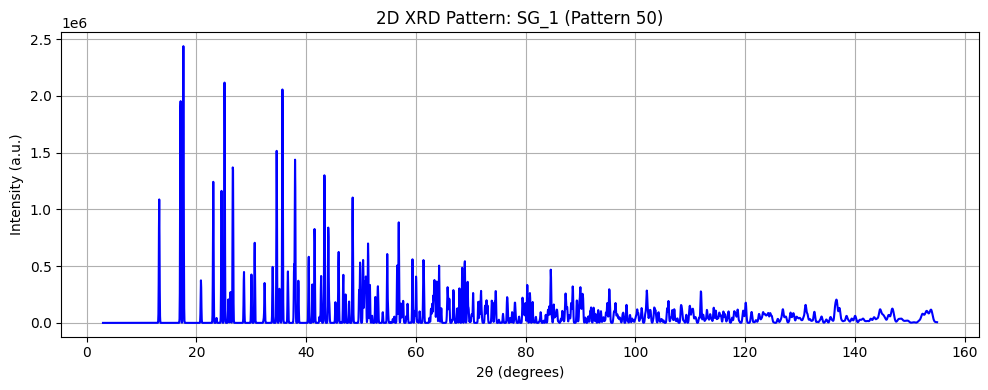

In [ ]:
import h5py
import matplotlib.pyplot as plt

# file_path = "your_file.h5"  # Replace with your actual file path
sg = "SG_1"  # Example space group
pattern_index = 50  # Pattern index to select (0-based)

with h5py.File(file_path, "r") as f:
    if sg not in f:
        raise KeyError(f"Space group '{sg}' not found in the file.")

    sg_group = f[sg]

    if "intensity" not in sg_group or "2theta" not in sg_group:
        raise KeyError(f"Required datasets 'intensity' or '2theta' not found in '{sg}'.")

    intensity_data = sg_group["intensity"][:]  # shape (num_patterns, num_points)
    twotheta_data = sg_group["2theta"][:]      # shape (num_points,)

    # Check intensity data shape
    if intensity_data.ndim == 2:
        num_patterns = intensity_data.shape[0]
        if pattern_index >= num_patterns:
            raise IndexError(f"Pattern index {pattern_index} out of range (0 to {num_patterns-1}).")
        intensity = intensity_data[pattern_index, :]
        twotheta = twotheta_data
    elif intensity_data.ndim == 1:
        print(f"Single pattern found in {sg}. Plotting without index selection.")
        intensity = intensity_data
        twotheta = twotheta_data
    else:
        raise ValueError(f"Unexpected data shape: intensity {intensity_data.shape}, 2theta {twotheta_data.shape}")

# Plot the 2D pattern
plt.figure(figsize=(10, 4))
plt.plot(twotheta, intensity, color='blue')
plt.title(f"2D XRD Pattern: {sg} (Pattern {pattern_index})")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()


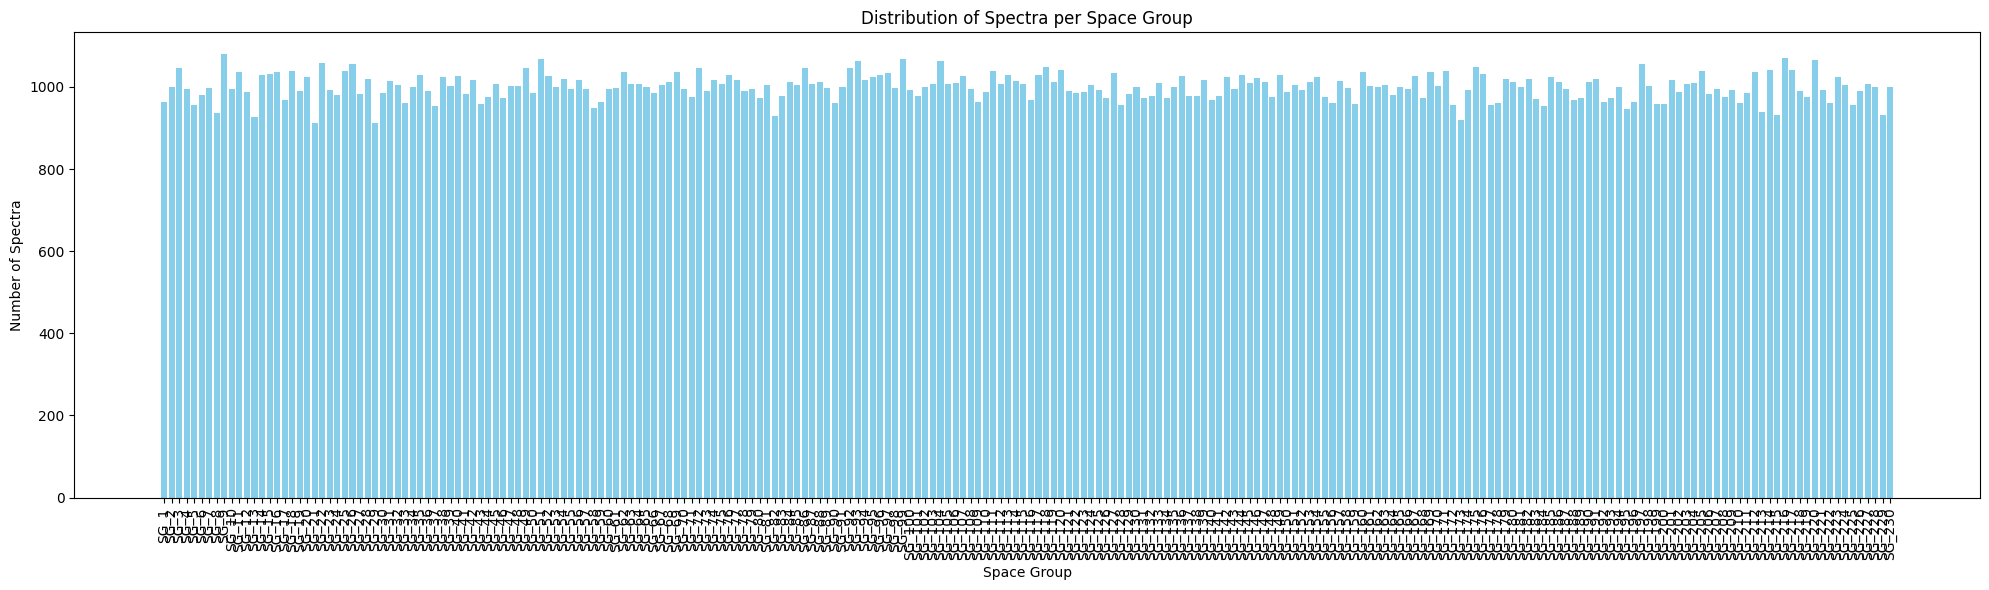

In [ ]:
import h5py
import matplotlib.pyplot as plt
from collections import defaultdict

#file_path = "your_file.h5"  # Replace with your actual file path

# Dictionary to store count per SG group
sg_counts = defaultdict(int)

with h5py.File(file_path, "r") as f:
    for sg_name in f.keys():
        try:
            sg_group = f[sg_name]
            if "intensity" in sg_group:
                intensity = sg_group["intensity"]
                if intensity.ndim == 1:
                    sg_counts[sg_name] = 1
                elif intensity.ndim == 2:
                    sg_counts[sg_name] = intensity.shape[0]
                else:
                    print(f"Skipping {sg_name}, unexpected intensity shape: {intensity.shape}")
            else:
                print(f"Skipping {sg_name}, 'intensity' dataset missing.")
        except KeyError as e:
            print(f"Skipping {sg_name} due to missing dataset: {e}")

# Sort space groups numerically by their integer part (e.g., SG_1 -> 1)
sorted_sg = sorted(sg_counts.items(), key=lambda x: int(x[0].split('_')[1]))

# Unpack for plotting
sg_labels, counts = zip(*sorted_sg)

# Plotting
plt.figure(figsize=(20, 6))
plt.bar(sg_labels, counts, color='skyblue')
plt.xticks(rotation=90)
plt.xlabel("Space Group")
plt.ylabel("Number of Spectra")
plt.title("Distribution of Spectra per Space Group")
plt.tight_layout()
plt.show()


# pattern data only - Data split and save

In [ ]:
import h5py
import numpy as np
import re
from tqdm import tqdm

# file_path = "your_file.h5"  # Replace with actual path

X = []
y = []

with h5py.File(file_path, "r") as f:
    # Iterate over all SG groups (e.g., SG_1, SG_2, ...)
    for sg_name in tqdm(f.keys(), desc="Processing space groups"):
        if not sg_name.startswith("SG_"):
            continue

        sg_id = int(re.findall(r"\d+", sg_name)[0])  # extract SG number
        sg_group = f[sg_name]

        if "intensity" not in sg_group:
            print(f"Skipping {sg_name}: missing 'intensity' dataset.")
            continue

        intensity_data = sg_group["intensity"][:]  # shape (num_patterns, num_points)

        # Iterate over all patterns in this SG group
        for i in range(intensity_data.shape[0]):
            intensity = intensity_data[i, :]  # 1D

            # Trim or pad to length 3041
            if len(intensity) >= 3041:
                trimmed = intensity[:3041]
            else:
                trimmed = np.pad(intensity, (0, 3041 - len(intensity)), mode='constant')

            X.append(trimmed)
            y.append(sg_id)

X = np.array(X, dtype=np.float32)  # All elements now have same length
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")


Processing space groups: 100%|██████████| 230/230 [01:55<00:00,  1.98it/s]


X shape: (230000, 3041), y shape: (230000,)


In [ ]:
import torch
import h5py
from sklearn.model_selection import train_test_split

# Adjust split ratios if needed
test_split = 0.20
validation_split = 0.20

# Convert X and y to PyTorch tensors
X1 = torch.tensor(X, dtype=torch.float32)  # ensure dtype is consistent with numpy array
y1 = torch.tensor(y, dtype=torch.long)

# First split: Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X1, y1, test_size=test_split, random_state=42, stratify=y1
)

# Second split: Train/Validation (20% of the train split)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=validation_split, random_state=42, stratify=y_train
)

# Save to HDF5
output_file = f"{data_path}{file_name}_test_{test_split}_val_{validation_split}.h5"
with h5py.File(output_file, "w") as f:
    f.create_dataset("X_train", data=X_train.numpy())
    f.create_dataset("y_train", data=y_train.numpy())
    f.create_dataset("X_val", data=X_val.numpy())
    f.create_dataset("y_val", data=y_val.numpy())
    f.create_dataset("X_test", data=X_test.numpy())
    f.create_dataset("y_test", data=y_test.numpy())

print(f"Data successfully split and saved to {output_file}")


Data successfully split and saved to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_pyCrysfml_high_res.hdf5_test_0.2_val_0.2.h5


# Normalization

In [ ]:
import torch
import h5py
import numpy as np
import os
import torch.nn.functional as F

# Adjust split ratios if needed
test_split = 0.20
validation_split = 0.20

def normalize_minmax(x):
    return (x - x.min(axis=1, keepdims=True)) / (x.max(axis=1, keepdims=True) - x.min(axis=1, keepdims=True) + 1e-8)

def normalize_zscore(x):
    return (x - x.mean(axis=1, keepdims=True)) / (x.std(axis=1, keepdims=True) + 1e-8)

def normalize_log(x):
    return np.log1p(x)

def save_normalized_versions(original_h5_path, data_path, file_name, test_split=0.2, validation_split=0.2):
    # Load the original HDF5 file
    with h5py.File(original_h5_path, "r") as f:
        X_train, y_train = f["X_train"][:], f["y_train"][:]
        X_val, y_val = f["X_val"][:], f["y_val"][:]
        X_test, y_test = f["X_test"][:], f["y_test"][:]

    # Convert to numpy if needed
    X_train = np.array(X_train)
    X_val = np.array(X_val)
    X_test = np.array(X_test)

    y_train = np.array(y_train)
    y_val = np.array(y_val)
    y_test = np.array(y_test)

    # Dictionary of normalization techniques
    normalizations = {
        "minmax": normalize_minmax,
        "zscore": normalize_zscore,
        "log": normalize_log
    }

    for norm_name, norm_func in normalizations.items():
        X_train_norm = norm_func(X_train.copy())
        X_val_norm = norm_func(X_val.copy())
        X_test_norm = norm_func(X_test.copy())

        # Save to a new HDF5 file
        output_file = os.path.join(data_path, f"{file_name}_{norm_name}_test_{test_split}_val_{validation_split}.h5")
        with h5py.File(output_file, "w") as f:
            f.create_dataset("X_train", data=X_train_norm.astype(np.float32))
            f.create_dataset("y_train", data=y_train)
            f.create_dataset("X_val", data=X_val_norm.astype(np.float32))
            f.create_dataset("y_val", data=y_val)
            f.create_dataset("X_test", data=X_test_norm.astype(np.float32))
            f.create_dataset("y_test", data=y_test)

        print(f"Saved {norm_name} normalized data to: {output_file}")


In [ ]:
original_h5_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_reflection_high_res_test_0.2_val_0.2.h5"
data_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"
file_name = "230K_reflection_high_res"

save_normalized_versions(original_h5_path, data_path, file_name)


Saved minmax normalized data to: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_reflection_high_res_minmax_test_0.2_val_0.2.h5
Saved zscore normalized data to: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_reflection_high_res_zscore_test_0.2_val_0.2.h5
Saved log normalized data to: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_reflection_high_res_log_test_0.2_val_0.2.h5


In [ ]:
import h5py
import numpy as np
import pandas as pd

file_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_pyCrysfml_high_res_minmax_test_0.2_val_0.2.h5"
#file_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_pyCrysfml_high_res_zscore_test_0.2_val_0.2.h5"
#file_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/230K_pyCrysfml_high_res_log_test_0.2_val_0.2.h5"

def load_and_summarize_h5(file_path):
    with h5py.File(file_path, 'r') as f:
        for split in ['train', 'val', 'test']:
            X = f[f'X_{split}'][:]
            y = f[f'y_{split}'][:]

            print(f"\n=== {split.upper()} SET ===")
            print(f"X_{split} shape: {X.shape}")
            print(f"y_{split} shape: {y.shape}")

            # Assuming X is 2D: samples x features
            print("Feature stats summary (X):")
            df = pd.DataFrame(X)
            print(df.describe().transpose())  # mean, std, min, max, quartiles

            # For label summary (y)
            unique, counts = np.unique(y, return_counts=True)
            print("Label distribution (y):")
            for label, count in zip(unique, counts):
                print(f"  Label {label}: {count} samples")

# Example usage:
#file_path = 'path_to_your_h5_file.h5'
load_and_summarize_h5(file_path)



=== TRAIN SET ===
X_train shape: (147200, 3041)
y_train shape: (147200,)
Feature stats summary (X):
         count      mean       std  min       25%       50%       75%  \
0     147200.0  0.000161  0.011589  0.0  0.000000  0.000000  0.000000   
1     147200.0  0.000111  0.007975  0.0  0.000000  0.000000  0.000000   
2     147200.0  0.000099  0.007778  0.0  0.000000  0.000000  0.000000   
3     147200.0  0.000111  0.008939  0.0  0.000000  0.000000  0.000000   
4     147200.0  0.000124  0.009350  0.0  0.000000  0.000000  0.000000   
...        ...       ...       ...  ...       ...       ...       ...   
3036  147200.0  0.003313  0.008676  0.0  0.000003  0.000067  0.002530   
3037  147200.0  0.003055  0.008302  0.0  0.000003  0.000048  0.002148   
3038  147200.0  0.002771  0.007827  0.0  0.000003  0.000035  0.001781   
3039  147200.0  0.002469  0.007263  0.0  0.000002  0.000027  0.001439   
3040  147200.0  0.002158  0.006612  0.0  0.000002  0.000021  0.001134   

           max  
0    

# t-SNE & UMAP

Loaded data shape: X=(230000, 1000), y=(230000,)
Running t-SNE...


/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Running UMAP...


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


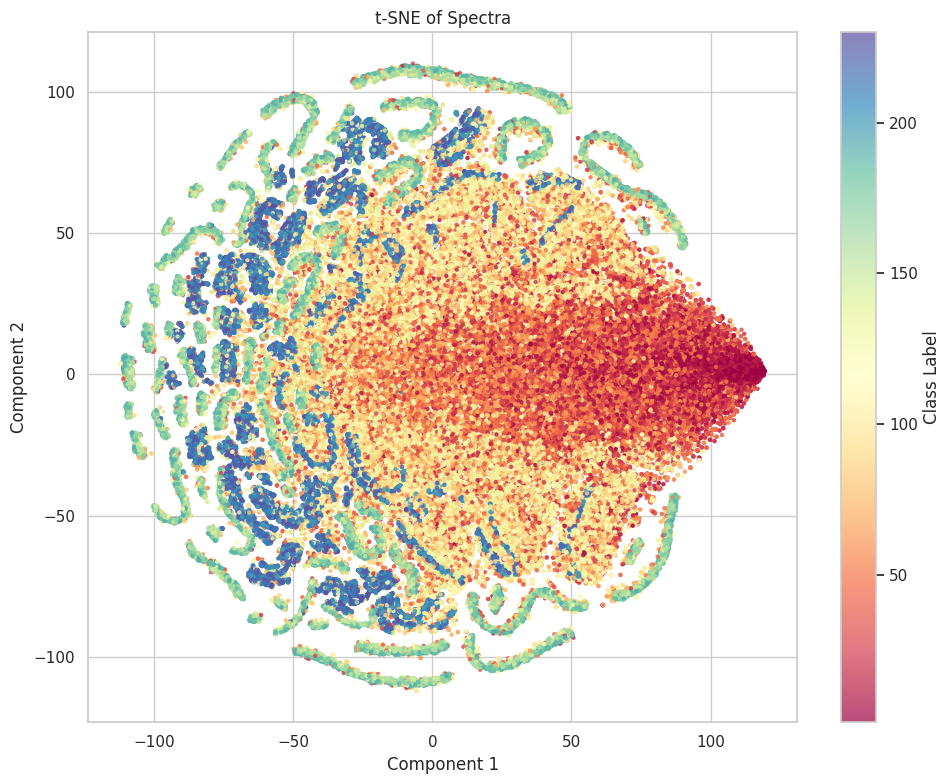

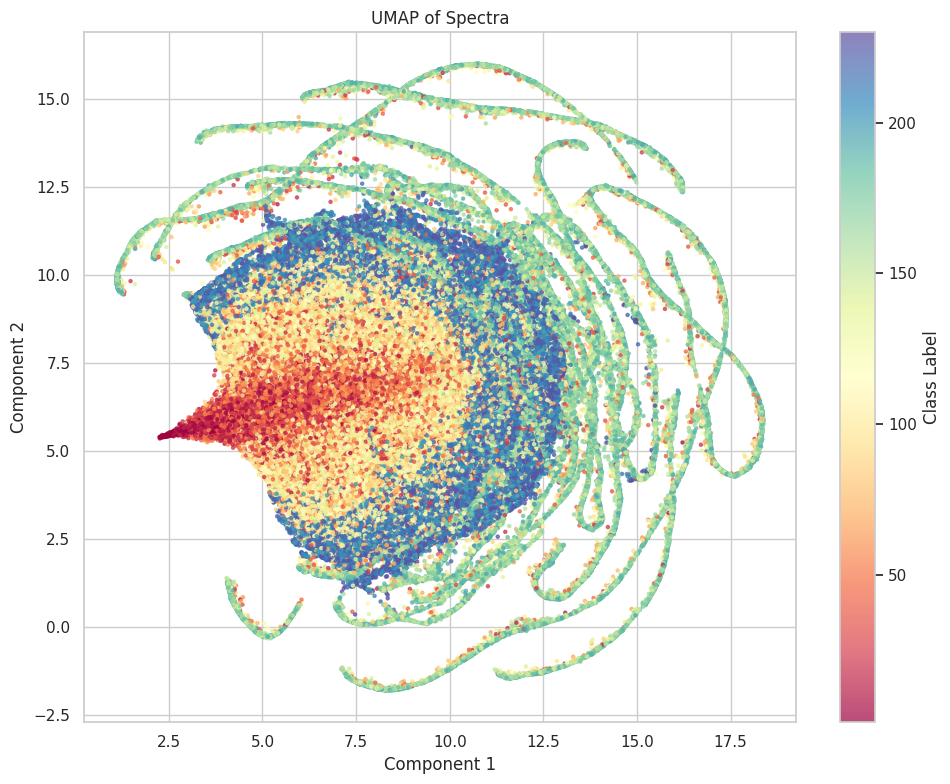

In [5]:
# ================================================
# 1. Import Libraries
# ================================================
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
import umap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Optional: enable inline plots if in notebook
%matplotlib inline
sns.set(style='whitegrid', context='notebook')

# ================================================
# 2. Load Data from HDF5
# ================================================
#file_path = "your_dataset.h5"  # <-- change this

with h5py.File(file_path, "r") as f:
    X = np.concatenate([f["X_train"][:], f["X_val"][:], f["X_test"][:]])
    y = np.concatenate([f["y_train"][:], f["y_val"][:], f["y_test"][:]])

print(f"Loaded data shape: X={X.shape}, y={y.shape}")

# ================================================
# 3. Preprocessing: Normalize for t-SNE/UMAP
# ================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Optional: use PCA to reduce dimensionality before t-SNE/UMAP
pca = PCA(n_components=50)
X_pca = pca.fit_transform(X_scaled)

# ================================================
# 4. Run t-SNE
# ================================================
print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca', random_state=42)
X_tsne = tsne.fit_transform(X_pca)

# ================================================
# 5. Run UMAP
# ================================================
print("Running UMAP...")
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_pca)

# ================================================
# 6. Plotting Function
# ================================================
def plot_embedding(X_embedded, y, title="Embedding"):
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y, cmap="Spectral", s=5, alpha=0.7)
    plt.title(title)
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.colorbar(scatter, label="Class Label")
    plt.tight_layout()
    plt.show()

# ================================================
# 7. Visualize
# ================================================
plot_embedding(X_tsne, y, title="t-SNE of Spectra")
plot_embedding(X_umap, y, title="UMAP of Spectra")
